# The experiment toolkit

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ashford-A/UniVII/blob/main/docs/tutorials/toolkit.ipynb)

This notebook walks through the parts added in UniVII 0.2 on simulated data, so every step can be checked
against a known answer:

1. a hyperbolic latent whose curvature and class prototypes are learned, with tree and pseudotime tools
2. a hidden Markov model that segments cells along pseudotime
3. a mosaic atlas from cohorts that measured different modalities
4. fitting a new cohort onto the trained atlas without changing it
5. comparing configurations across seeds
6. stain normalisation for image tiles

The data are simulated and small, so the numbers here show that each tool does what it says. They are not a
benchmark.

In [1]:
import os, sys
os.environ["TQDM_DISABLE"] = "1"                      # no progress bars in the saved notebook
if "google.colab" in sys.modules:
    %pip install -q "univii[tutorials]>=0.2"

In [2]:
# Training length. Raise it for real data.
N_EPOCHS = 40

In [3]:
import warnings
import numpy as np
import pandas as pd
import torch
import anndata as ad
import matplotlib.pyplot as plt

import univii
from univii import (ModalityConfig, TrainingConfig, UniVIConfig, UniVIMultiModalVAE, UniVITrainer,
                    make_loader, presets)
from univii.geometry import tree_distance_matrix

import logging
logging.disable(logging.INFO)                         # keep the trainer's per-epoch log out of the notebook
warnings.filterwarnings("ignore")
QUIET = dict(log_every=10**9)
print("univii", univii.__version__)

univii 0.2.0


## Simulated cells on a known tree

Six cell types sit on a small differentiation tree. Each cell has two modalities, `rna` (60 features) and
`adt` (12 features), both generated from the same position on the tree.

In [4]:
PARENTS = {"stem": None, "myeloid": "stem", "lymphoid": "stem", "mono": "myeloid", "gran": "myeloid", "B": "lymphoid"}
NAMES = list(PARENTS)
tree_dist, _, depth = tree_distance_matrix(PARENTS, order=NAMES)

def simulate(n_cells, seed, shift=None):
    """Cells whose features follow a random walk down the tree (children differ from parents by a step)."""
    rng = np.random.default_rng(0)                       # the tree's feature programs are fixed
    profile = {}
    for name in NAMES:
        parent = PARENTS[name]
        profile[name] = (np.zeros(72) if parent is None else profile[parent]) + 1.5 * rng.normal(size=72)
    rng = np.random.default_rng(seed)
    codes = rng.integers(0, len(NAMES), n_cells)
    x = np.stack([profile[NAMES[c]] for c in codes]) + 0.4 * rng.normal(size=(n_cells, 72))
    if shift is not None:
        x = x + shift
    obs = pd.DataFrame({"celltype": [NAMES[c] for c in codes]}, index=[f"cell{seed}_{i}" for i in range(n_cells)])
    rna = ad.AnnData(x[:, :60].astype(np.float32), obs=obs.copy())
    adt = ad.AnnData(x[:, 60:].astype(np.float32), obs=obs.copy())
    return rna, adt, codes

rna, adt, codes = simulate(900, seed=1)
labels = np.array(NAMES)[codes]
print(rna.shape, adt.shape, dict(pd.Series(labels).value_counts()))

(900, 60) (900, 12) {'lymphoid': np.int64(169), 'stem': np.int64(158), 'gran': np.int64(152), 'B': np.int64(145), 'mono': np.int64(141), 'myeloid': np.int64(135)}


## 1. A learned hyperbolic space

Three things are learned here beyond the encoders and decoders:

- the **curvature** of the space (`learn_curvature=True`),
- one **prototype per cell type**, placed in hyperbolic space (`prior="mog"` with `prior_label_head`),
- the arrangement of those prototypes, pulled toward the tree (`prior_tree_weight`).

In [5]:
torch.manual_seed(0)
cfg = UniVIConfig(
    latent_dim=4,
    modalities=[ModalityConfig("rna", 60, [64], [64]), ModalityConfig("adt", 12, [32], [32])],
    latent_geometry="hyperbolic", learn_curvature=True,
    prior="mog", prior_components=len(NAMES), prior_label_head="celltype", prior_tree_weight=2.0,
)
model = UniVIMultiModalVAE(cfg)
model.set_hierarchy(tree_dist, root_index=NAMES.index("stem"))
print("curvature before training:", round(float(model.curvature), 3))

loader = make_loader({"rna": rna, "adt": adt}, labels={"celltype": codes}, batch_size=128, shuffle=True)
history = UniVITrainer(model, loader, train_cfg=TrainingConfig(n_epochs=N_EPOCHS, lr=3e-3, **QUIET)).fit()
print("curvature after training: ", round(float(model.curvature), 3))

curvature before training: 1.0


curvature after training:  0.757


Anchor the coordinates at the stem cells, so that distance from the origin means distance from the root,
then embed the cells and read off the prototypes.

cells assigned to their own type's prototype: 1.0


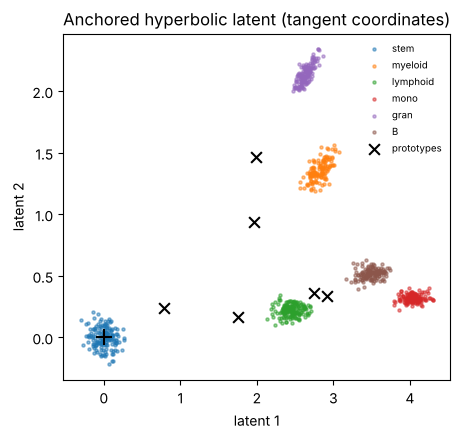

In [6]:
model.eval()
x_all = {"rna": torch.as_tensor(rna.X), "adt": torch.as_tensor(adt.X)}
with torch.no_grad():
    model.set_latent_anchor(model.encode_fused(x_all)[0][labels == "stem"])
    z = model.encode_fused(x_all, anchored=True)[0].numpy()
    centres = model.prior_centres().numpy()
    assigned = model.prior_responsibilities(model.encode_fused(x_all)[0]).argmax(1).numpy()

geo = dict(geometry=model.latent_geometry, hyperbolic_dim=model.latent.hyperbolic_dim, curvature=float(model.curvature))
print("cells assigned to their own type's prototype:", round(float((assigned == codes).mean()), 3))

fig, ax = plt.subplots(figsize=(5, 4.5))
for i, name in enumerate(NAMES):
    ax.scatter(*z[labels == name][:, :2].T, s=5, alpha=0.5, label=name)
ax.scatter(*centres[:, :2].T, c="k", marker="x", s=60, label="prototypes")
ax.scatter(0, 0, c="k", marker="+", s=120)
ax.set(xlabel="latent 1", ylabel="latent 2", title="Anchored hyperbolic latent (tangent coordinates)")
ax.legend(fontsize=7, frameon=False); plt.show()

### Tree and pseudotime

`cluster_tree` joins the cell types into a tree using geodesic distances, and `tree_agreement` compares it
with the tree the data were simulated from. `graph_pseudotime` measures distance from the stem cells along a
neighbour graph.

In [7]:
from univii.hierarchy import cluster_tree, graph_pseudotime, tree_agreement

tree = cluster_tree(z, labels, root="stem", **geo)
print("recovered parents:", tree["parents"])
print("agreement with the true tree:", {k: round(v, 3) for k, v in tree_agreement(tree["parents"], PARENTS).items()})

pseudotime = graph_pseudotime(z, labels == "stem", k=15, **geo)
true_depth = np.array([depth[NAMES.index(n)] for n in labels])
print(pd.DataFrame({"depth in tree": true_depth, "pseudotime": pseudotime}).groupby("depth in tree").mean().round(2))

recovered parents: {'stem': None, 'lymphoid': 'stem', 'myeloid': 'stem', 'mono': 'myeloid', 'gran': 'myeloid', 'B': 'lymphoid'}
agreement with the true tree: {'edge_jaccard': 1.0, 'path_spearman': 1.0, 'parent_accuracy': 1.0}
               pseudotime
depth in tree            
0.0                  0.00
1.0                  3.02
2.0                  6.47


## 2. Segmenting cells along pseudotime

`segment_by_order` sorts the cells by pseudotime and fits a hidden Markov model to their latent coordinates
in that order, giving each cell a state. States are runs along the ordering, so this is a way to ask where
along a trajectory the latent changes regime. Here it is run on one lineage.

In [8]:
from univii.hmm import segment_by_order

lineage = np.isin(labels, ["stem", "myeloid", "mono"])
states, probabilities, hmm = segment_by_order(z[lineage], order=pseudotime[lineage], n_states=3, n_iter=150)
print(pd.crosstab(pd.Series(labels[lineage], name="cell type"), pd.Series(states, name="HMM state")))

HMM state    0    1    2
cell type               
mono         0    0  141
myeloid      0  135    0
stem       158    0    0


## 3. A mosaic atlas

Now split the cells into three cohorts that measured different things: RNA only, protein only, and a
smaller paired cohort that bridges them. `make_mosaic_loader` draws each batch from one cohort and labels
every cell with its cohort. `presets.atlas_config` conditions the decoders on the cohort, pulls the cohorts
together in the latent, and turns encoder batch normalisation off. `cycle_weight` adds cycle consistency,
which also runs through the modality a cohort is missing.

In [9]:
from univii.atlas import (adapt_to_cohort, cohort_mixing, encode_cohort, label_purity, make_mosaic_loader,
                          transfer_labels)

idx = np.random.default_rng(0).permutation(rna.n_obs)
a, b, c = idx[:350], idx[350:700], idx[700:]
cohorts = {"rna_only": {"rna": rna[a].copy()}, "adt_only": {"adt": adt[b].copy()},
           "bridge": {"rna": rna[c].copy(), "adt": adt[c].copy()}}
mosaic = make_mosaic_loader(cohorts, batch_size=64, ratios=[1, 1, 2],
                            labels={"bridge": {"celltype": codes[c]}}, seed=0)
print("cohort codes:", mosaic.cohort_codes)

torch.manual_seed(0)
atlas_cfg = presets.atlas_config({"rna": 60, "adt": 12}, n_cohorts=3, latent_dim=8, cycle_weight=1.0)
atlas = UniVIMultiModalVAE(atlas_cfg)
UniVITrainer(atlas, mosaic, train_cfg=TrainingConfig(n_epochs=N_EPOCHS, lr=3e-3, **QUIET)).fit()

z_by_cohort = {name: encode_cohort(atlas, data, cohort=mosaic.cohort_codes[name]) for name, data in cohorts.items()}
z_atlas = np.vstack(list(z_by_cohort.values()))
cohort_of = np.repeat(list(cohorts), [len(a), len(b), len(c)])
type_of = np.r_[labels[a], labels[b], labels[c]]
print("cohort mixing (0 = separate, about 1 = mixed):", round(cohort_mixing(z_atlas, cohort_of), 2))
print("label purity  (1 = neighbours share the type):", round(label_purity(z_atlas, type_of), 2))

cohort codes: {'rna_only': 0, 'adt_only': 1, 'bridge': 2}


cohort mixing (0 = separate, about 1 = mixed): 0.84
label purity  (1 = neighbours share the type): 1.0


Only the bridge cohort had labels during training. Transfer them to the two single-modality cohorts and
check against the truth, which we know because the data are simulated.

In [10]:
for name, members in (("rna_only", a), ("adt_only", b)):
    result = transfer_labels(z_by_cohort["bridge"], labels[c], z_by_cohort[name], k=15)
    print(f"{name}: accuracy {np.mean(result['label'].to_numpy() == labels[members]):.3f}, "
          f"mean confidence {result['confidence'].mean():.2f}, median novelty {result['novelty'].median():.2f}")

rna_only: accuracy 1.000, mean confidence 1.00, median novelty 1.14
adt_only: accuracy 1.000, mean confidence 1.00, median novelty 1.48


## 4. Adding a cohort to a trained atlas

A fourth cohort arrives later, with a technical shift in its RNA measurements. `adapt_to_cohort` freezes the
atlas and learns only a per-feature shift for the new cohort, plus its row in the decoders' cohort
embedding. The existing cohorts' embeddings do not change.

In [11]:
shift = np.zeros(72); shift[:60] = 1.2 * np.random.default_rng(5).normal(size=60)
rna_new, _, codes_new = simulate(300, seed=7, shift=shift)
new = {"rna": rna_new}

z_before = encode_cohort(atlas, new)                              # treated as if it were an existing cohort
result = adapt_to_cohort(atlas, make_loader(new, batch_size=64, shuffle=True), reference_z=z_atlas,
                         n_epochs=N_EPOCHS, lr=0.05)
z_after = encode_cohort(atlas, new, cohort=result["code"])

who = np.r_[cohort_of, ["new"] * 300]
print("new cohort code:", result["code"])
print("mixing before adapting:", round(cohort_mixing(np.vstack([z_atlas, z_before]), who), 2))
print("mixing after adapting: ", round(cohort_mixing(np.vstack([z_atlas, z_after]), who), 2))
learned = atlas.input_shifts["rna"].weight[result["code"]].detach().numpy()
print("learned shift vs the true correction (cosine):",
      round(float(learned @ -shift[:60] / (np.linalg.norm(learned) * np.linalg.norm(shift[:60]))), 3))
print("atlas embeddings unchanged:",
      all(np.array_equal(encode_cohort(atlas, data, cohort=mosaic.cohort_codes[n]), z_by_cohort[n]) for n, data in cohorts.items()))

new cohort code: 3
mixing before adapting: 0.58


mixing after adapting:  0.87
learned shift vs the true correction (cosine): 0.994
atlas embeddings unchanged: True


## 5. Comparing configurations

`compare_models` trains each variant for each seed and collects whatever metrics you compute. Here the
question is which latent geometry best preserves the tree, measured by how well distances between cell-type
centres track distances in the tree.

In [12]:
from scipy.stats import spearmanr
from univii.experiments import compare_models, summarize
from univii.hierarchy import cluster_centroids

def tree_fidelity(m):
    with torch.no_grad():
        zz = m.encode_fused(x_all)[0].numpy()
    g = dict(geometry=m.latent_geometry, hyperbolic_dim=m.latent.hyperbolic_dim, curvature=float(m.curvature))
    cen, names = cluster_centroids(zz, labels, **g)
    d = univii.geometry.pairwise_latent_distance(cen, **g)
    iu = np.triu_indices(len(names), 1)
    order = [NAMES.index(n) for n in names]
    return {"tree_spearman": spearmanr(d[iu], tree_dist[np.ix_(order, order)][iu]).statistic,
            "label_purity": label_purity(zz, labels, **g)}

dims = {"rna": 60, "adt": 12}
variants = {geometry: presets.paired_config(dims, latent_dim=4, latent_geometry=geometry)
            for geometry in ("euclidean", "hyperbolic", "product")}
runs = compare_models(variants, loader, evaluate=tree_fidelity, seeds=(0, 1),
                      train_cfg=TrainingConfig(n_epochs=N_EPOCHS, lr=3e-3, **QUIET))
summarize(runs)[["n_seeds", "tree_spearman", "label_purity", "train_seconds"]].round(3)

n_seeds tree_spearman        label_purity      train_seconds       
                            mean    std         mean  std          mean    std
variant                                                                       
euclidean        2         0.801  0.034          1.0  0.0         1.469  0.132
hyperbolic       2         0.876  0.083          1.0  0.0         3.781  0.132
product          2         0.749  0.049          1.0  0.0         4.234  0.002

Two seeds on one small simulated dataset is enough to show the mechanics, not to rank the geometries. For
a real comparison use more seeds, held-out cells, and your own data.

## 6. Stain normalisation

`MacenkoNormalizer` estimates the two stain colours of a slide and re-renders its tiles with the colours of
a reference slide. The tiles below are simulated from known stain colours, so the error against the
correctly stained version can be measured.

mean pixel error before: 0.0674
mean pixel error after:  0.0053


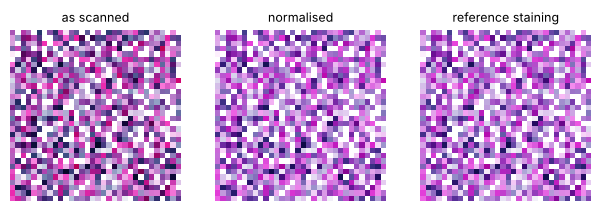

In [13]:
from univii.histology import MacenkoNormalizer

def render(amounts, stains, scale=1.0):
    return np.exp(-(amounts * scale) @ stains.T).transpose(0, 3, 1, 2)

rng = np.random.default_rng(0)
reference_stains = np.array([[0.65, 0.07], [0.70, 0.99], [0.29, 0.11]]); reference_stains /= np.linalg.norm(reference_stains, axis=0)
other_stains = reference_stains + np.array([[0.10, -0.04], [-0.08, 0.02], [0.06, 0.10]]); other_stains /= np.linalg.norm(other_stains, axis=0)
amounts = rng.exponential(0.6, size=(8, 32, 32, 2)); amounts[rng.random((8, 32, 32)) < 0.15] = 0.0

reference_slide = render(rng.exponential(0.6, size=(8, 32, 32, 2)), reference_stains)
wanted, shifted = render(amounts, reference_stains), render(amounts, other_stains, 1.3)   # same tissue, two stainings
fixed = MacenkoNormalizer().fit(reference_slide).transform(shifted)
print("mean pixel error before:", round(float(np.abs(shifted - wanted).mean()), 4))
print("mean pixel error after: ", round(float(np.abs(fixed - wanted).mean()), 4))

fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.7))
for ax, img, title in zip(axes, (shifted[0], fixed[0], wanted[0]), ("as scanned", "normalised", "reference staining")):
    ax.imshow(np.clip(img.transpose(1, 2, 0), 0, 1)); ax.set_title(title, fontsize=9); ax.axis("off")
plt.show()

## Where to go next

- The [toolkit guide](../user_guide/toolkit.md) describes every option used here, with its limits.
- The [latent geometry guide](../user_guide/latent_geometry.md) covers anchoring and tree supervision.
- The [spatial guide](../user_guide/spatial_and_conv.md) covers image tiles, the graph encoder and the spatial prior.